# plotnine-linter demo

Load the extension once; every plot after that is linted as it appears. Findings show under the plot, with a fix and a *Why it matters* note.

In [2]:
%load_ext plotnine_linter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from plotnine import *

rng = np.random.default_rng(108)
regions = pd.DataFrame({
    'region_name': ['West', 'East', 'South', 'North', 'Central'],
    'avg_income_usd': [52, 61, 47, 58, 50],
})

In [3]:
%plotlint rules 

Tier 1 — Errors
  AX101  [on ] error    Bar or area axis excludes zero
  AX102  [on ] error    Dual y-axes
  AX103  [on ] error    Log scale silently drops data
  CL101  [on ] error    Rainbow colormap for ordered data
  CL102  [on ] error    Too many categorical colors
  LB101  [on ] error    Quantitative axis has no label
  LY101  [on ] error    Overlapping tick labels
  LY102  [on ] error    Legend covers data
  LY103  [on ] error    Low-contrast text
  MK101  [on ] error    Overplotting
  MK102  [on ] error    3D for 2D data
  MK103  [on ] error    Line connects unordered categories
Tier 2 — Clarity
  AX201  [on ] warning  Unsorted bars on a nominal axis
  AX202  [on ] warning  Rotated or crowded category labels
  AX203  [on ] warning  Free facet scales
  AX204  [on ] warning  Default histogram bins
  AX205  [on ] warning  Ordered categories in alphabetical order
  AX206  [on ] info     Log values on a linear axis
  AX207  [on ] warning  Fractional ticks on whole-number data
  CL201  [on ] warning  Colors indistinguishable with color-vision deficiency
  CL202  [on ] warning  Diverging data on a sequential color scale
  CL203  [on ] warning  Color that encodes nothing
  CL204  [on ] warning  Low-contrast marks
  LB201  [on ] warning  Label is a raw variable name
  LB203  [on ] warning  Redundant legend
  LB205  [on ] info     Label doesn't match the values
  LB206  [on ] warning  Scientific offset on an axis
  LY201  [on ] warning  Text too small at final size
  LY202  [on ] warning  Legend order doesn't match line order
  MK201  [on ] warning  Pie with many slices
  MK202  [on ] warning  Spaghetti lines
  MK203  [on ] warning  Summary bars without uncertainty
  MK204  [on ] warning  Box plot hides small groups
  MK205  [on ] warning  Stacked bars with many segments
Tier 3 — Style (opt-in)
  CL301  [off] info     Color is the only cue
  LB301  [off] info     Quantitative label has no units
  ST301  [off] info     No title
  ST303  [off] info     Direct labels would beat a legend
  ST305  [off] info     Same category, different colors across figures
  ST306  [off] info     Inconsistent themes across figures
  ST307  [off] info     Excess precision in tick labels

## A typical first draft

Truncated bars, raw column names as labels, alphabetical order, and a legend that repeats the axis.

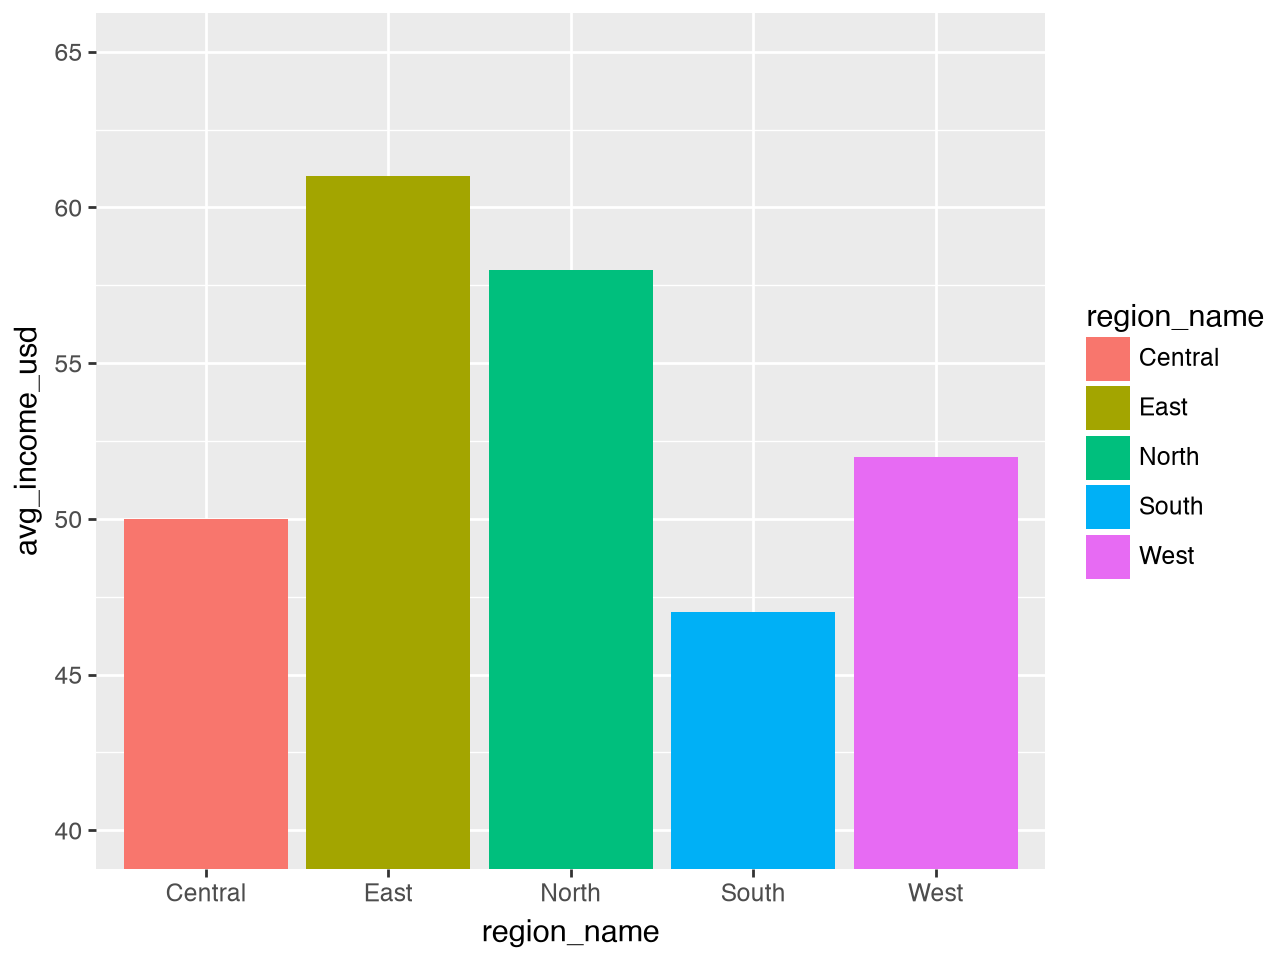

plotnine-linter: 5 issue(s)
AX101 error: `geom_col` draws bars from zero, but the value axis shows 38.8 to 66.2, so bar lengths are not proportional.
    fix: Drop `ylim()`, `coord_cartesian(ylim=...)` or the scale `limits=` so the bars start at zero; if the zoom matters, use `geom_point()` or `geom_line()`.
AX201 warning: The 5 bars for `region_name` are in alphabetical order, not sorted by value.
    fix: `aes(x='reorder(region_name, avg_income_usd)')`, or make `region_name` an ordered Categorical sorted by value. Suppress if the order is meaningful.
LB201 warning: The x-axis is labeled `region_name`, the raw variable name.
    fix: `+ labs(x='Region name')`
LB201 warning: The y-axis is labeled `avg_income_usd`, the raw variable name.
    fix: `+ labs(y='Avg income (USD)')`
LB203 warning: `region_name` is mapped to both x and fill, so the legend repeats the x-axis.
    fix: Drop `fill='region_name'` and use one color (the axis already names each category); save color for another variable or a highlight.

In [4]:
(ggplot(regions, aes('region_name', 'avg_income_usd', fill='region_name'))
 + geom_col()
 + coord_cartesian(ylim=(40, 65)))

## After following the fixes

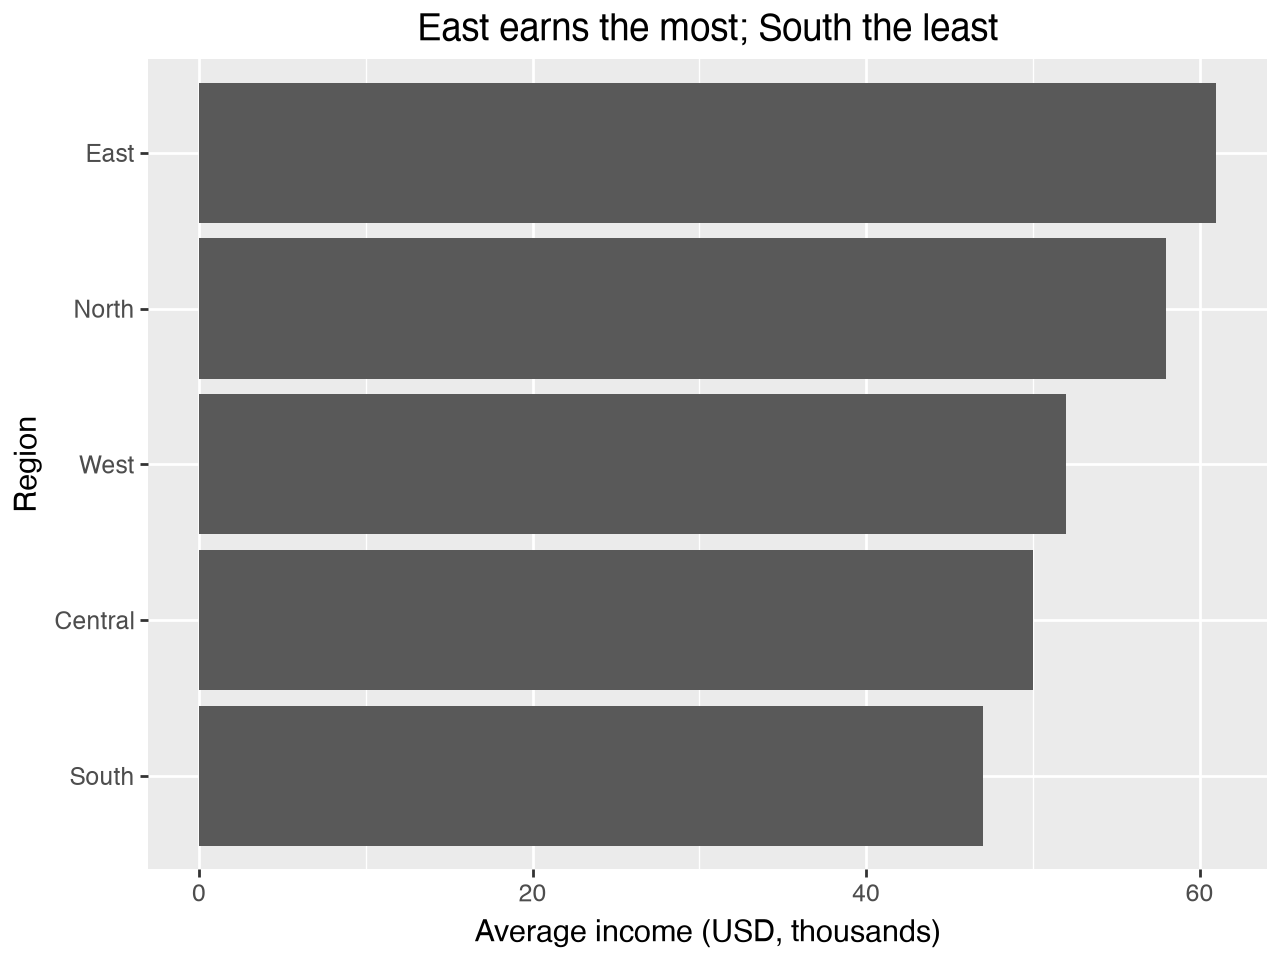

In [5]:
(ggplot(regions, aes('reorder(region_name, avg_income_usd)', 'avg_income_usd'))
 + geom_col()
 + coord_flip()
 + labs(x='Region', y='Average income (USD, thousands)',
        title='East earns the most; South the least'))

## matplotlib works too

The same rules run on any matplotlib figure, including pandas and seaborn plots.

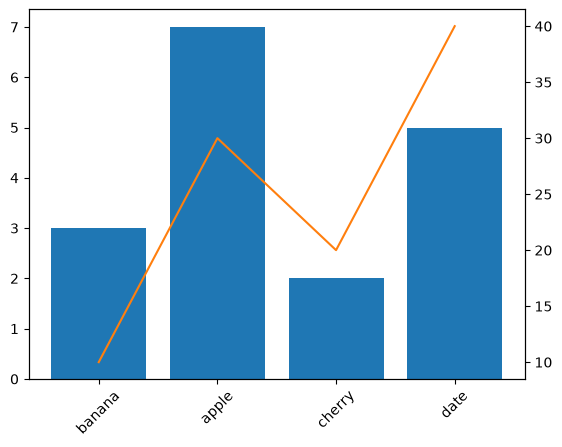

plotnine-linter: 6 issue(s)
AX102 error (panel 2): This figure overlays two axes with independent scales (`twinx`/`twiny`).
    fix: Use `fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)`, or index both series (e.g. percent change from the first value) and plot them on one axis.
LB101 error (panel 1): The y-axis shows numbers but has no label.
    fix: `ax.set_ylabel('What is measured (units)')`
LB101 error (panel 2): The y-axis shows numbers but has no label.
    fix: `ax.set_ylabel('What is measured (units)')`
MK103 error (panel 2): A line connects categories on the x-axis that have no inherent order.
    fix: Use `ax.scatter` or `ax.bar`; suppress if the categories are ordered.
AX201 warning (panel 1): The 4 bars aren't sorted by value.
    fix: Sort before plotting, e.g. `counts.sort_values().plot.barh()`; suppress if the order is meaningful.
AX202 warning (panel 1): Category labels on the x-axis are rotated 45° (e.g. 'banana').
    fix: Swap the axes with a horizontal layout (`barh`, or swap x and y) so the labels read horizontally.

In [6]:
fig, ax = plt.subplots()
ax.bar(['banana', 'apple', 'cherry', 'date'], [3, 7, 2, 5])
ax.tick_params(axis='x', labelrotation=45)
ax2 = ax.twinx()
ax2.plot([0, 1, 2, 3], [10, 30, 20, 40], color='tab:orange')
plt.show()

## Overplotting

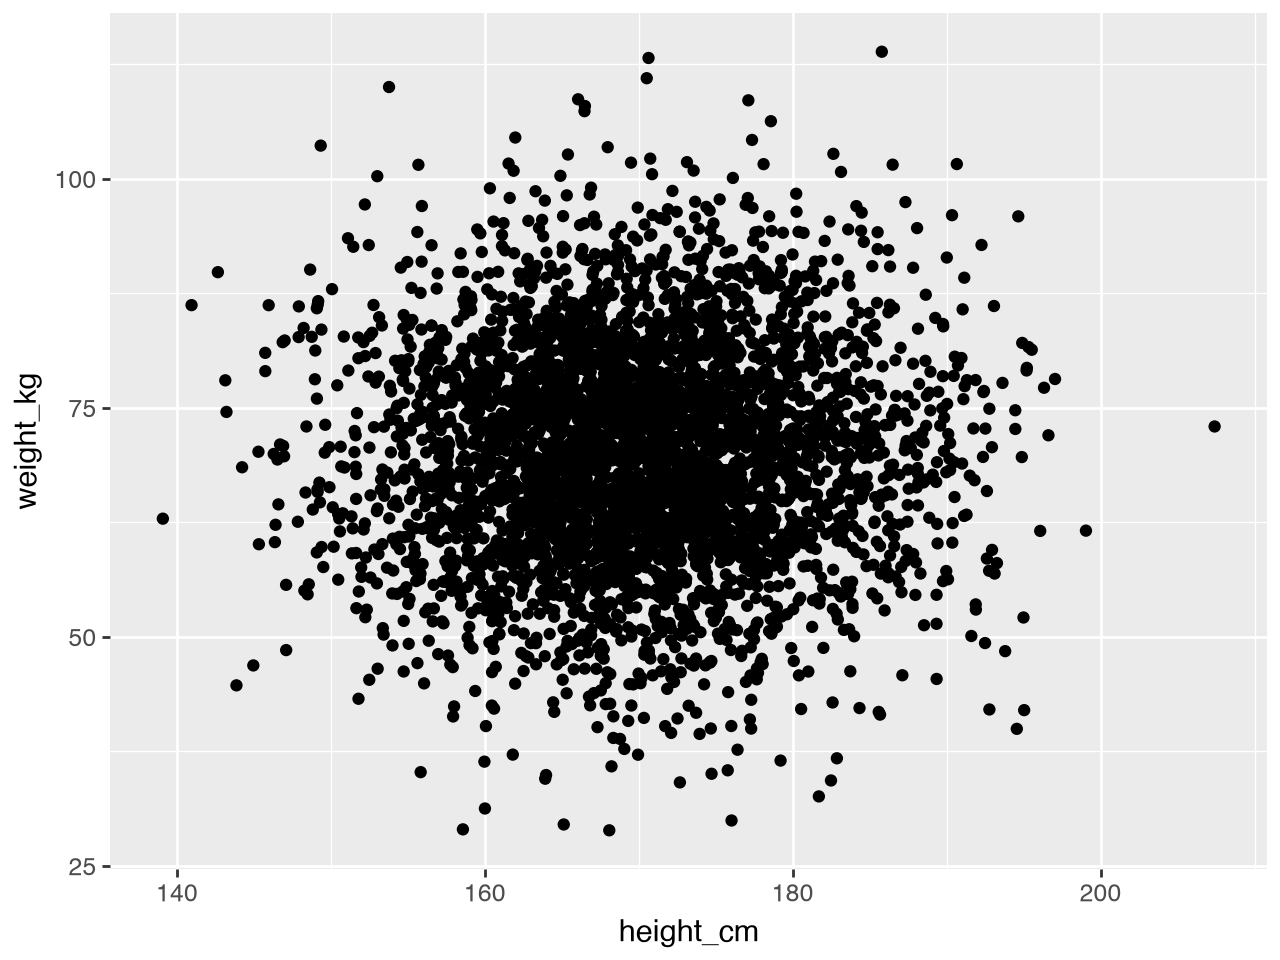

plotnine-linter: 3 issue(s)
MK101 error: 76% of the 4000 points overlap another point at full opacity.
    fix: `geom_point(alpha=0.3)`, or `geom_bin_2d()` for very large data.
LB201 warning: The x-axis is labeled `height_cm`, the raw variable name.
    fix: `+ labs(x='Height (cm)')`
LB201 warning: The y-axis is labeled `weight_kg`, the raw variable name.
    fix: `+ labs(y='Weight (kg)')`

In [7]:
cloud = pd.DataFrame({'height_cm': rng.normal(170, 9, 4000), 'weight_kg': rng.normal(70, 12, 4000)})
ggplot(cloud, aes('height_cm', 'weight_kg')) + geom_point()

## Breaking a rule on purpose

Suppress a rule for one cell with a comment that says why. Without a reason, the report notes the missing reason.

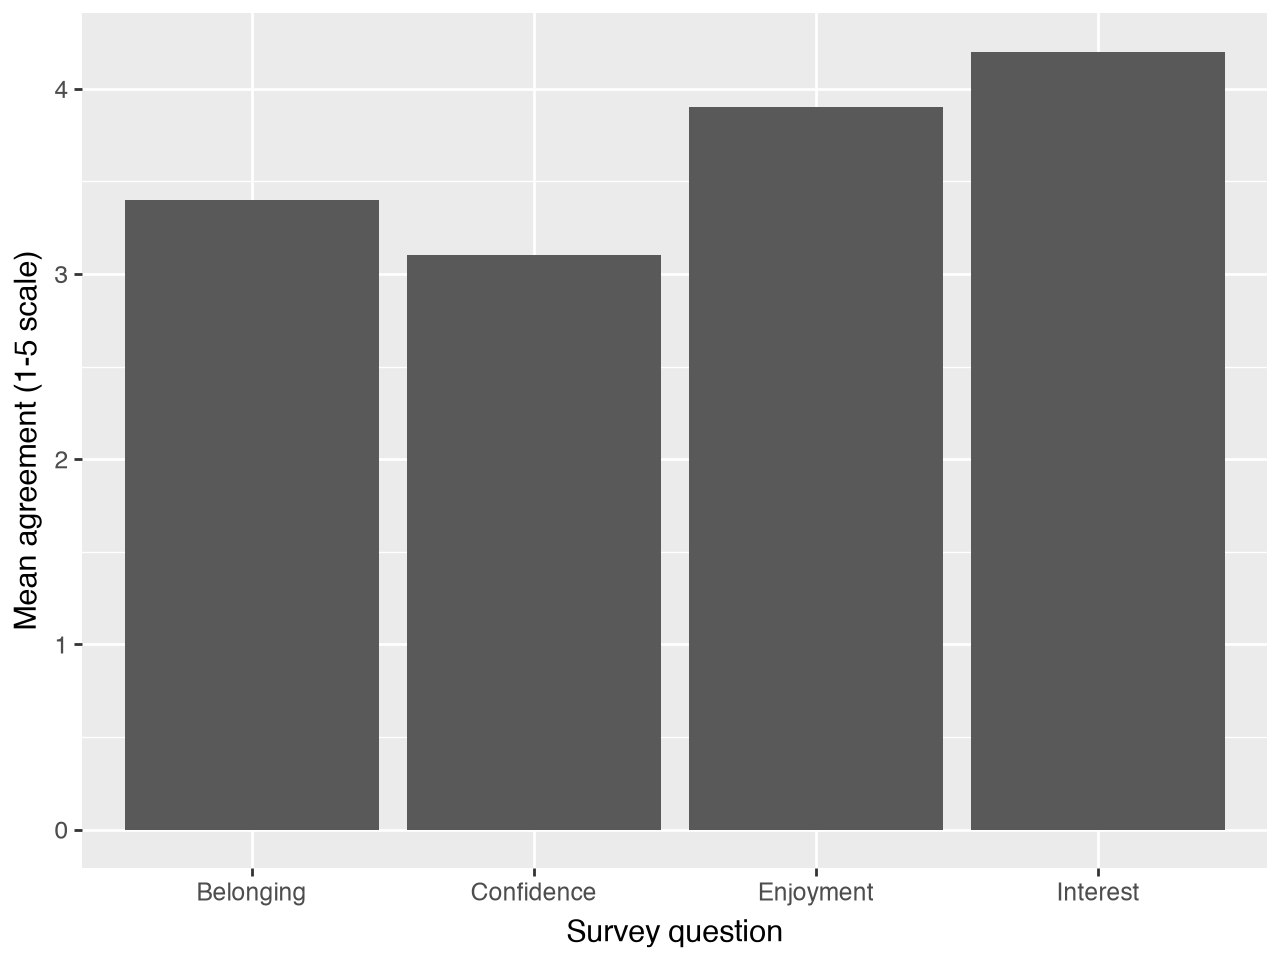

In [8]:
# plotlint: ignore[AX201] survey questions are listed in the order they were asked
survey = pd.DataFrame({'question': ['Enjoyment', 'Confidence', 'Belonging', 'Interest'],
                       'mean_score': [3.9, 3.1, 3.4, 4.2]})
(ggplot(survey, aes('question', 'mean_score'))
 + geom_col()
 + labs(x='Survey question', y='Mean agreement (1-5 scale)'))

## Plots shown with `.show()` are linted too

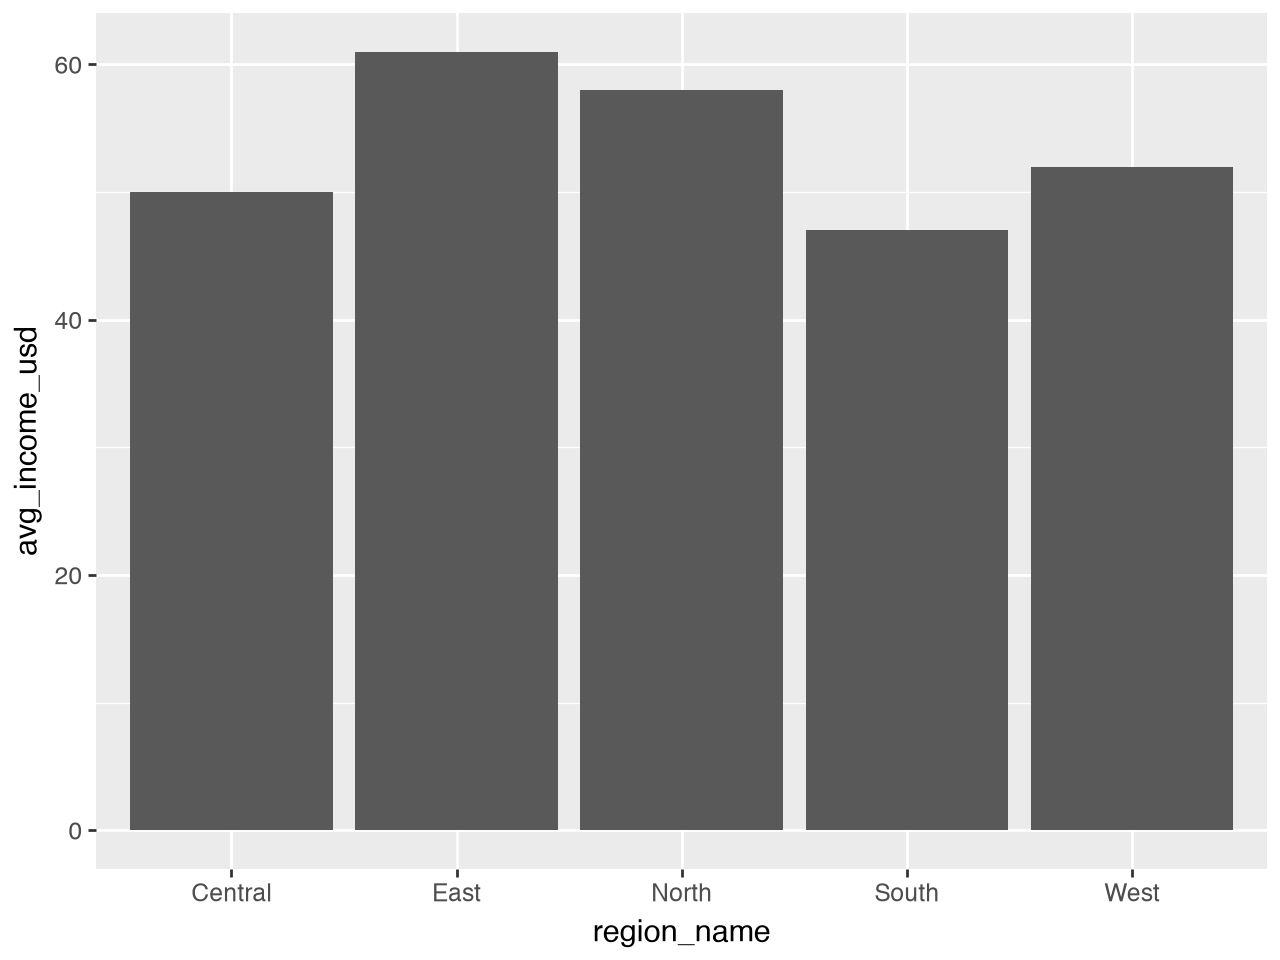

plotnine-linter: 3 issue(s)
AX201 warning: The 5 bars for `region_name` are in alphabetical order, not sorted by value.
    fix: `aes(x='reorder(region_name, avg_income_usd)')`, or make `region_name` an ordered Categorical sorted by value. Suppress if the order is meaningful.
LB201 warning: The x-axis is labeled `region_name`, the raw variable name.
    fix: `+ labs(x='Region name')`
LB201 warning: The y-axis is labeled `avg_income_usd`, the raw variable name.
    fix: `+ labs(y='Avg income (USD)')`

In [9]:
(ggplot(regions, aes('region_name', 'avg_income_usd')) + geom_col()).show()

## Turning it off and on

plotnine-linter off


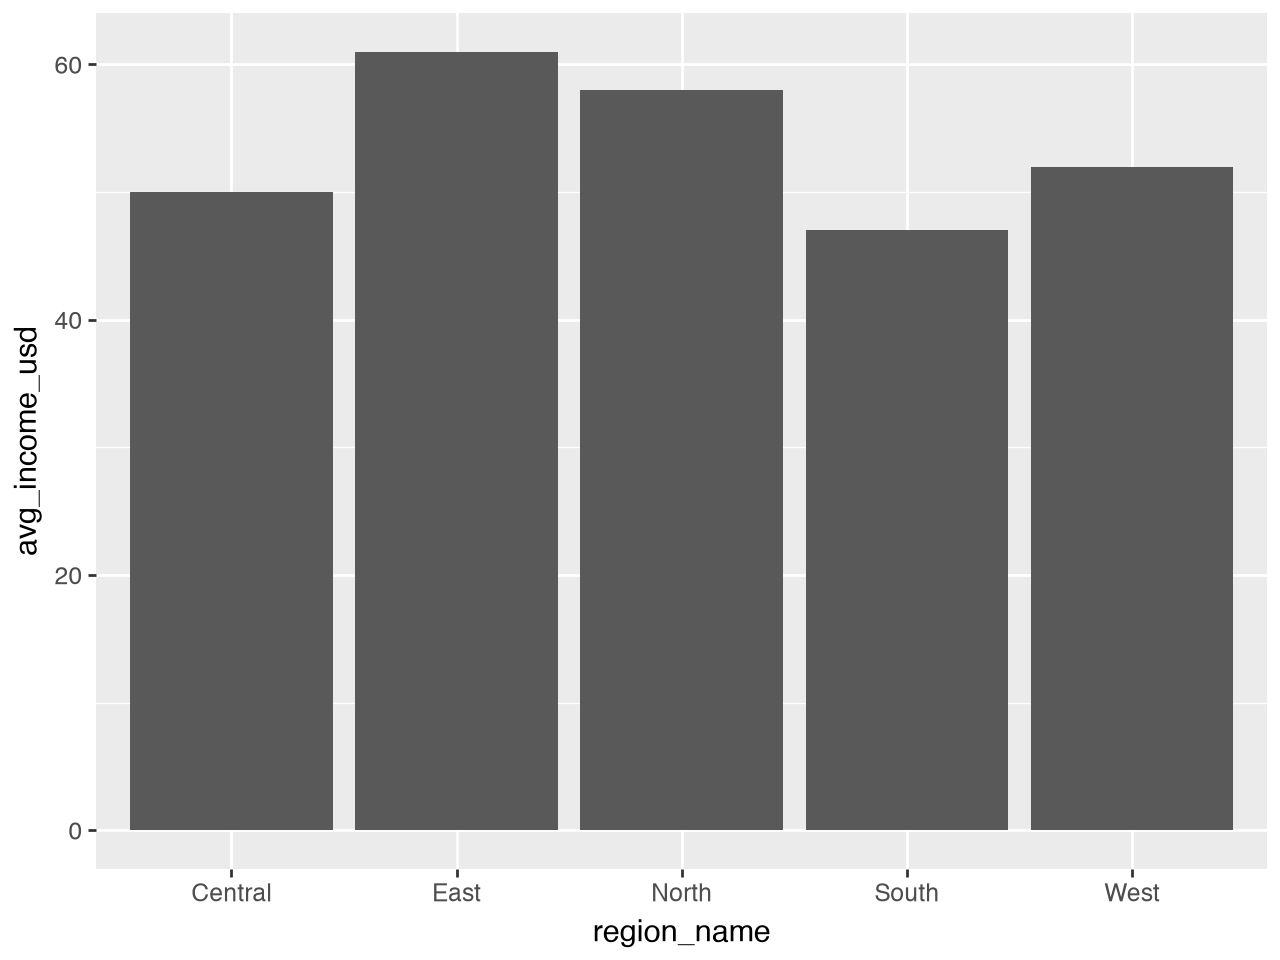

In [10]:
%plotlint off
ggplot(regions, aes('region_name', 'avg_income_usd')) + geom_col()

plotnine-linter on
plotnine-linter options: {'select': ['tier1']}


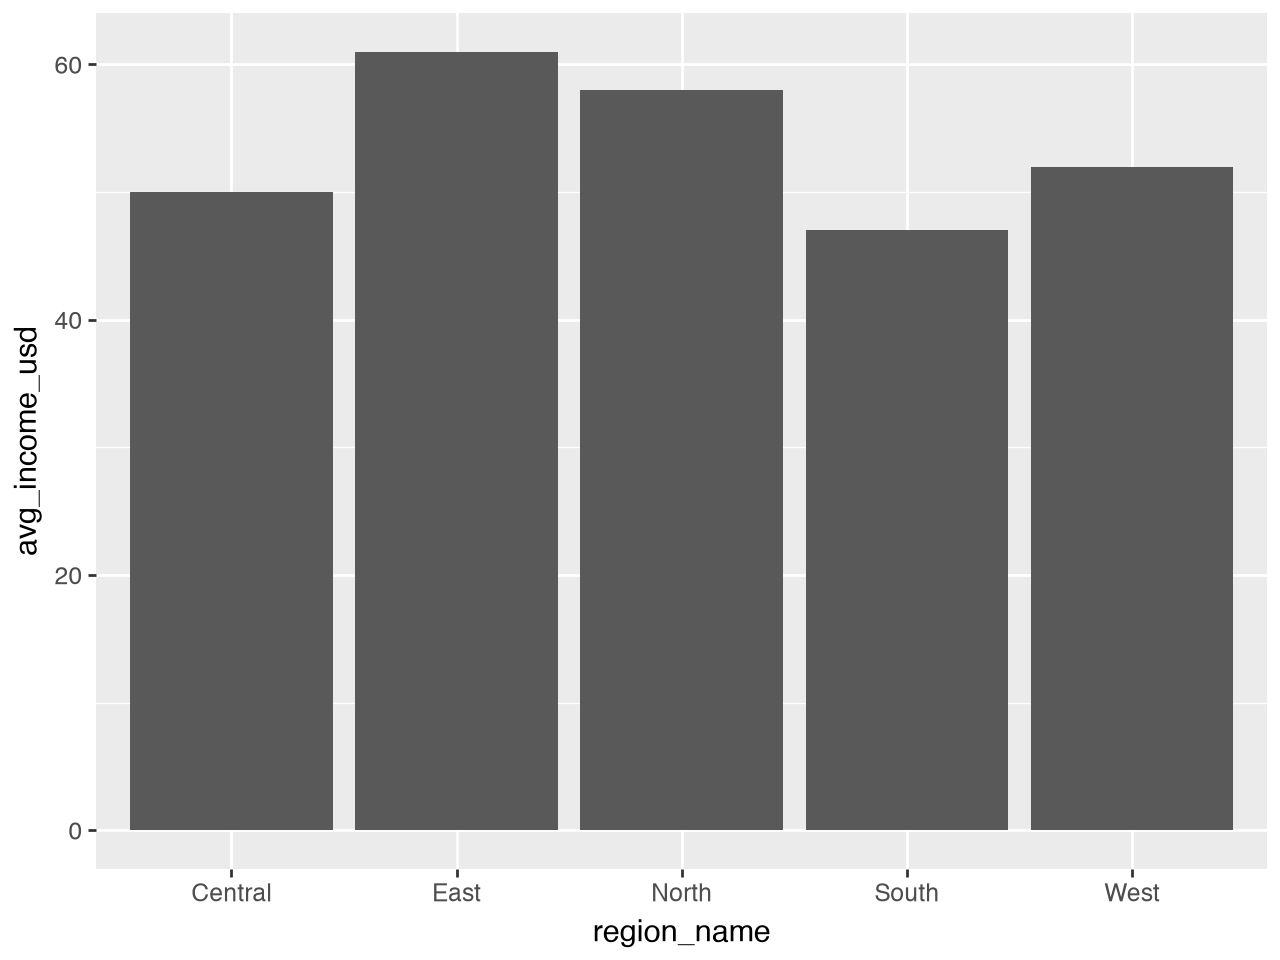

In [11]:
%plotlint on
%plotlint select=tier1
ggplot(regions, aes('region_name', 'avg_income_usd')) + geom_col()

In [12]:
%plotlint reset

plotnine-linter reset: options, summary and cross-figure memory cleared


## Opting into the style rules (tier 3)

Tier 3 rules are off by default: they're matters of taste or polish (no title, a legend that direct labels would beat, too many decimal places, inconsistent colors across figures). Turn them all on with `tier3`, or pick single rules by ID. This chart is clean under the default rules; tier 3 adds a few suggestions.

plotnine-linter options: {'select': ['tier1', 'tier2', 'tier3']}


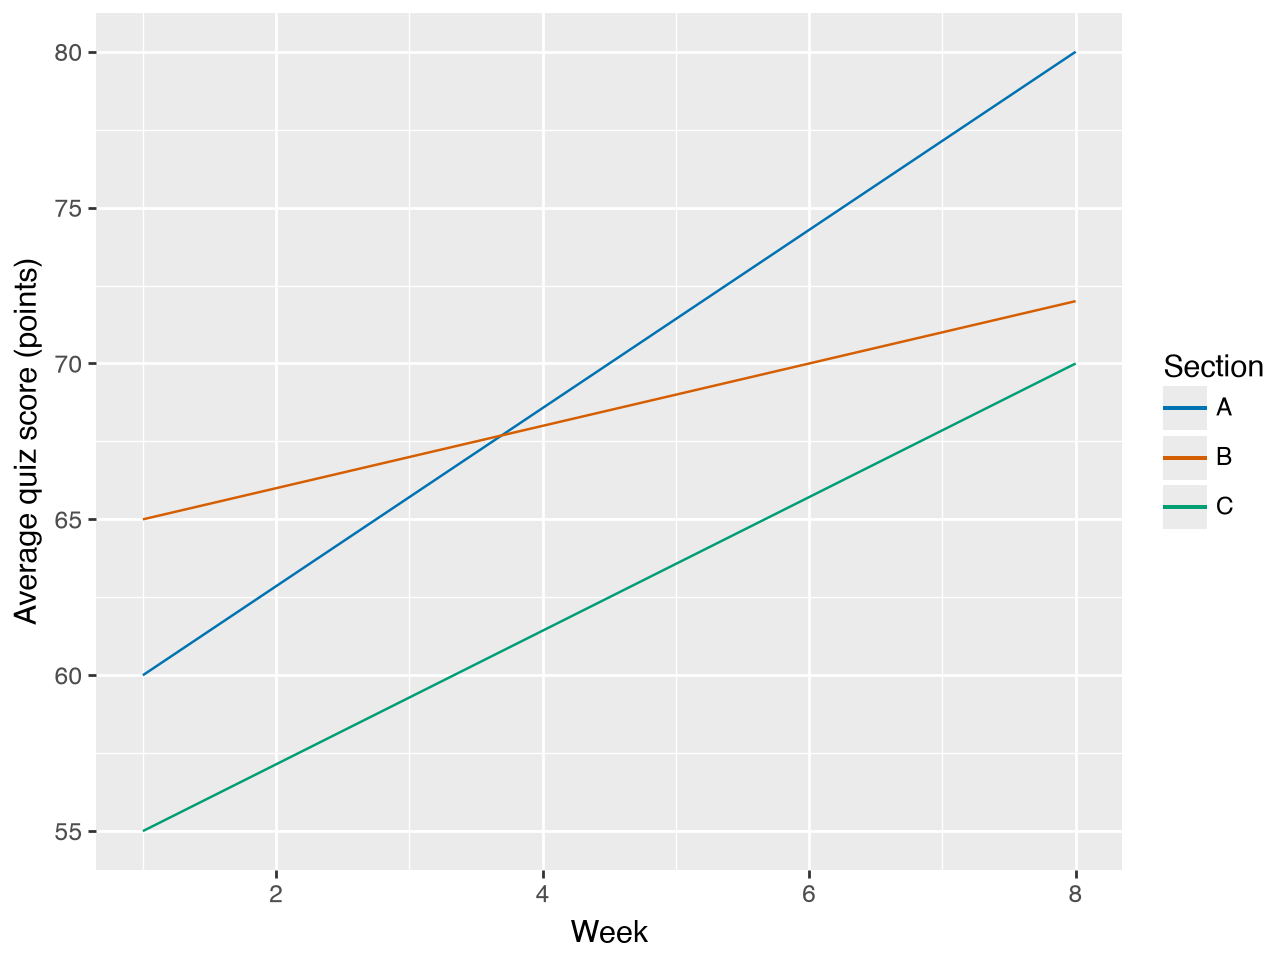

plotnine-linter: 3 issue(s)
CL301 info: `section` is shown by color alone, and in grayscale 'B' and 'C' look the same.
    fix: Also map `shape='section'` (points) or `linetype='section'` (lines), or label the groups directly with `geom_text`.
ST301 info: The plot has no title.
    fix: `+ labs(title='What the reader should take away')`
ST303 info: 3 lines are matched to a legend.
    fix: Label line ends with `geom_text` on the last point per group, then `+ theme(legend_position='none')`.

In [13]:
%plotlint select=tier1,tier2,tier3
trend = pd.DataFrame({'week': list(range(1, 9)) * 3,
                      'section': ['A'] * 8 + ['B'] * 8 + ['C'] * 8,
                      'score': np.r_[np.linspace(60, 80, 8), np.linspace(65, 72, 8), np.linspace(55, 70, 8)]})
(ggplot(trend, aes('week', 'score', color='section'))
 + geom_line()
 + scale_color_manual(values=['#0072B2', '#D55E00', '#009E73'])
 + labs(x='Week', y='Average quiz score (points)', color='Section'))

The same choice in code or for a whole course:

```python
lint(p, select=['tier1', 'tier2', 'tier3'])   # or select=['tier1', 'tier2', 'ST301']
```

```toml
# pyproject.toml
[tool.plotnine-linter]
select = ["tier1", "tier2", "ST301", "ST307"]
```

In [14]:
%plotlint select=tier1,tier2

plotnine-linter options: {'select': ['tier1', 'tier2']}


## In code: `lint()` returns a report

Use it in scripts, tests or an autograder.

In [15]:
from plotnine_linter import lint

report = lint(ggplot(regions, aes('region_name', 'avg_income_usd')) + geom_col())
print(report)
print()
print('Draft alt text:', report.alt_text)
report.ids

plotnine-linter: 3 issue(s)
AX201 warning: The 5 bars for `region_name` are in alphabetical order, not sorted by value.
    fix: `aes(x='reorder(region_name, avg_income_usd)')`, or make `region_name` an ordered Categorical sorted by value. Suppress if the order is meaningful.
LB201 warning: The x-axis is labeled `region_name`, the raw variable name.
    fix: `+ labs(x='Region name')`
LB201 warning: The y-axis is labeled `avg_income_usd`, the raw variable name.
    fix: `+ labs(y='Avg income (USD)')`

Draft alt text: Bar chart of avg_income_usd by region_name. Highest: East (61); lowest: South (47).


['AX201', 'LB201', 'LB201']

## A few more rules

These came out of calibrating the linter on past COGS 108 projects: problems students make often that the first rule set missed.

**Diverging data on a sequential colormap (CL202).** Correlations run from −1 to 1, so zero needs its own color.

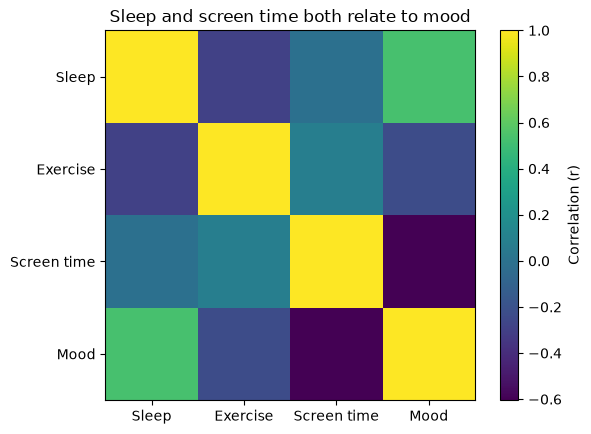

plotnine-linter: 1 issue(s)
CL202 warning: The colored values run from negative to positive, but the colormap `viridis` is sequential, so zero has no distinct color.
    fix: Pass `cmap='RdBu_r', vmin=-m, vmax=m` (seaborn heatmap: `cmap='vlag', center=0`).

In [16]:
scores = pd.DataFrame(rng.normal(size=(60, 4)), columns=['Sleep', 'Exercise', 'Screen time', 'Mood'])
scores['Mood'] = scores['Sleep'] - 0.8 * scores['Screen time'] + rng.normal(size=60)
corr = scores.corr()

fig, ax = plt.subplots()
im = ax.imshow(corr, cmap='viridis')
ax.set_xticks(range(4), corr.columns)
ax.set_yticks(range(4), corr.columns)
fig.colorbar(im, label='Correlation (r)')
ax.set_title('Sleep and screen time both relate to mood')
plt.show()

**Color that encodes nothing (CL203)** and **fractional ticks on whole numbers (AX207).**

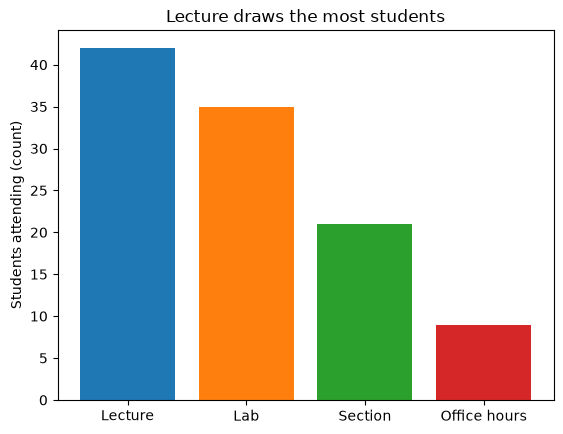

plotnine-linter: 1 issue(s)
CL203 warning: Each of the 4 bars has its own color, but the colors don't stand for anything.
    fix: Use one color: `ax.bar(x, y, color='#4C72B0')` (seaborn: `color=` instead of `palette=`).

In [17]:
fig, ax = plt.subplots()
ax.bar(['Lecture', 'Lab', 'Section', 'Office hours'], [42, 35, 21, 9], color=['C0', 'C1', 'C2', 'C3'])
ax.set_ylabel('Students attending (count)')
ax.set_title('Lecture draws the most students')
plt.show()

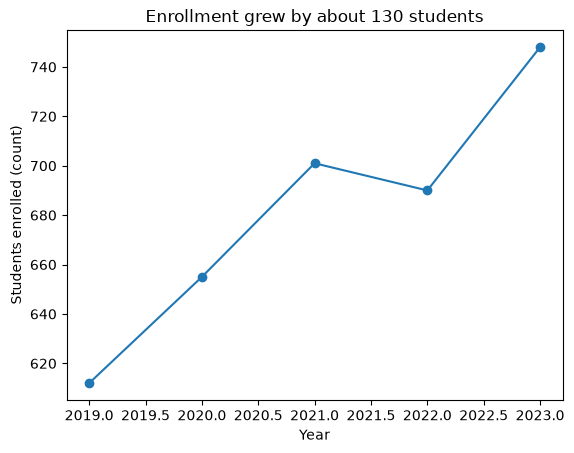

plotnine-linter: 1 issue(s)
AX207 warning: The x-axis has a tick at 2018.5, but the plotted values are whole numbers.
    fix: `from matplotlib.ticker import MaxNLocator`; `ax.xaxis.set_major_locator(MaxNLocator(integer=True))`.

In [18]:
enrollment = pd.DataFrame({'year': [2019, 2020, 2021, 2022, 2023], 'students': [612, 655, 701, 690, 748]})
fig, ax = plt.subplots()
ax.plot(enrollment.year, enrollment.students, marker='o')
ax.set(xlabel='Year', ylabel='Students enrolled (count)', title='Enrollment grew by about 130 students')
plt.show()

## Accessibility

**Low-contrast text (LY103)** is an error at any setting: WCAG asks for 4.5:1.

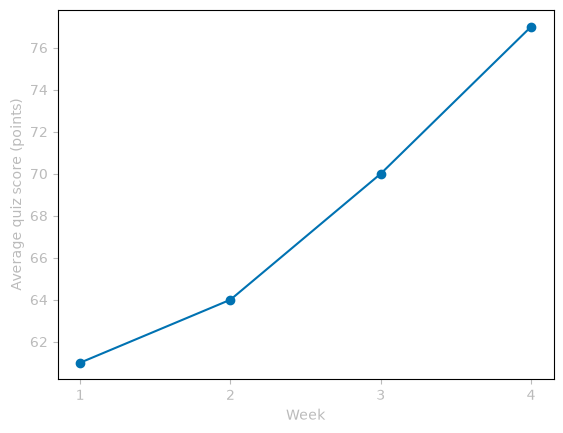

plotnine-linter: 1 issue(s)
LY103 error: Text 'Week' (xlabel) has a contrast of 1.9:1 against its background; it needs 4.5:1.
    fix: Darken it (`color='#222222'`), or lighten what is behind it.

In [19]:
fig, ax = plt.subplots()
ax.plot([1, 2, 3, 4], [61, 64, 70, 77], marker='o', color='#0072B2')
ax.set_xticks([1, 2, 3, 4])
ax.set_xlabel('Week', color='#bbbbbb')
ax.set_ylabel('Average quiz score (points)', color='#bbbbbb')
ax.tick_params(colors='#bbbbbb')
plt.show()

The **accessibility profile** turns on every rule tied to a [Chartability](https://chartability.github.io/POUR-CAF/) test or WCAG criterion, at their published thresholds (3:1 contrast for marks, at least 9 pt text). `show_rules('a11y')` lists them. See `docs/ACCESSIBILITY.md` for what a linter can and can't check.

In [20]:
from plotnine_linter import show_rules

show_rules('a11y')

Tier 1 — Errors
  CL101  [on ] error    Rainbow colormap for ordered data
  CL102  [on ] error    Too many categorical colors
  LB101  [on ] error    Quantitative axis has no label
  LY101  [on ] error    Overlapping tick labels
  LY102  [on ] error    Legend covers data
  LY103  [on ] error    Low-contrast text
  MK101  [on ] error    Overplotting
  MK102  [on ] error    3D for 2D data
Tier 2 — Clarity
  CL201  [on ] warning  Colors indistinguishable with color-vision deficiency
  CL204  [on ] warning  Low-contrast marks
  LB201  [on ] warning  Label is a raw variable name
  LB205  [on ] info     Label doesn't match the values
  LB206  [on ] warning  Scientific offset on an axis
  LY201  [on ] warning  Text too small at final size
  MK202  [on ] warning  Spaghetti lines
  MK203  [on ] warning  Summary bars without uncertainty
  MK204  [on ] warning  Box plot hides small groups
  MK205  [on ] warning  Stacked bars with many segments
Tier 3 — Style (opt-in)
  CL301  [off] info     Color is the only cue
  LB301  [off] info     Quantitative label has no units
  ST301  [off] info     No title
  ST305  [off] info     Same category, different colors across figures
  ST306  [off] info     Inconsistent themes across figures
  ST307  [off] info     Excess precision in tick labels

matplotlib's default orange is 2.5:1 against white: fine by default, flagged under the profile.

plotnine-linter profile: accessibility (Rules tied to Chartability tests and WCAG success criteria, at their published thresholds (marks 3:1, text at least 9 pt).)


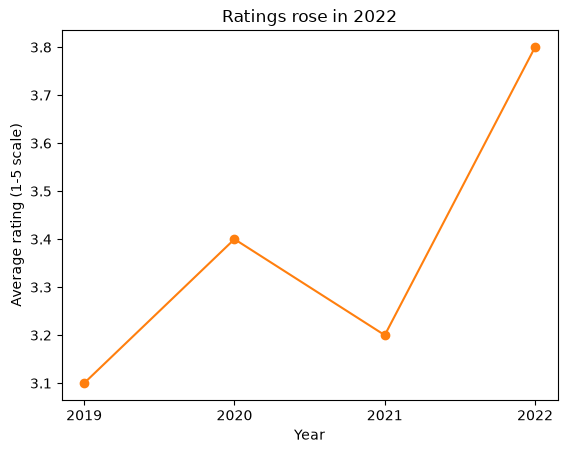

plotnine-linter: 1 issue(s)
CL204 warning: Marks colored #ff7f0e have a contrast of only 2.5:1 against the #ffffff background (WCAG asks 3:1).
    fix: Pick a darker color, or outline light fills: `ax.bar(..., edgecolor='#333333')`.

In [21]:
%plotlint profile accessibility
fig, ax = plt.subplots()
ax.plot([2019, 2020, 2021, 2022], [3.1, 3.4, 3.2, 3.8], color='tab:orange', marker='o')
ax.set_xticks([2019, 2020, 2021, 2022])
ax.set(xlabel='Year', ylabel='Average rating (1-5 scale)', title='Ratings rose in 2022')
plt.show()

In [22]:
%plotlint profile none

plotnine-linter profile cleared


## Accessibility audit

`lint()` reports problems. `%plotlint audit` (or `audit(p)`) goes through all 50 [Chartability](https://chartability.github.io/POUR-CAF/) tests and gives each a verdict for the last plot:

- **Pass** / **Fail**: decided by the linter's rules
- **Partly checked**: the linter gathered evidence (a draft alt text, abbreviations, the chart's reading grade) and asks you a question
- **Your call**: only you can decide; the audit asks
- **N/A**: about interactive or web charts, not a static plot

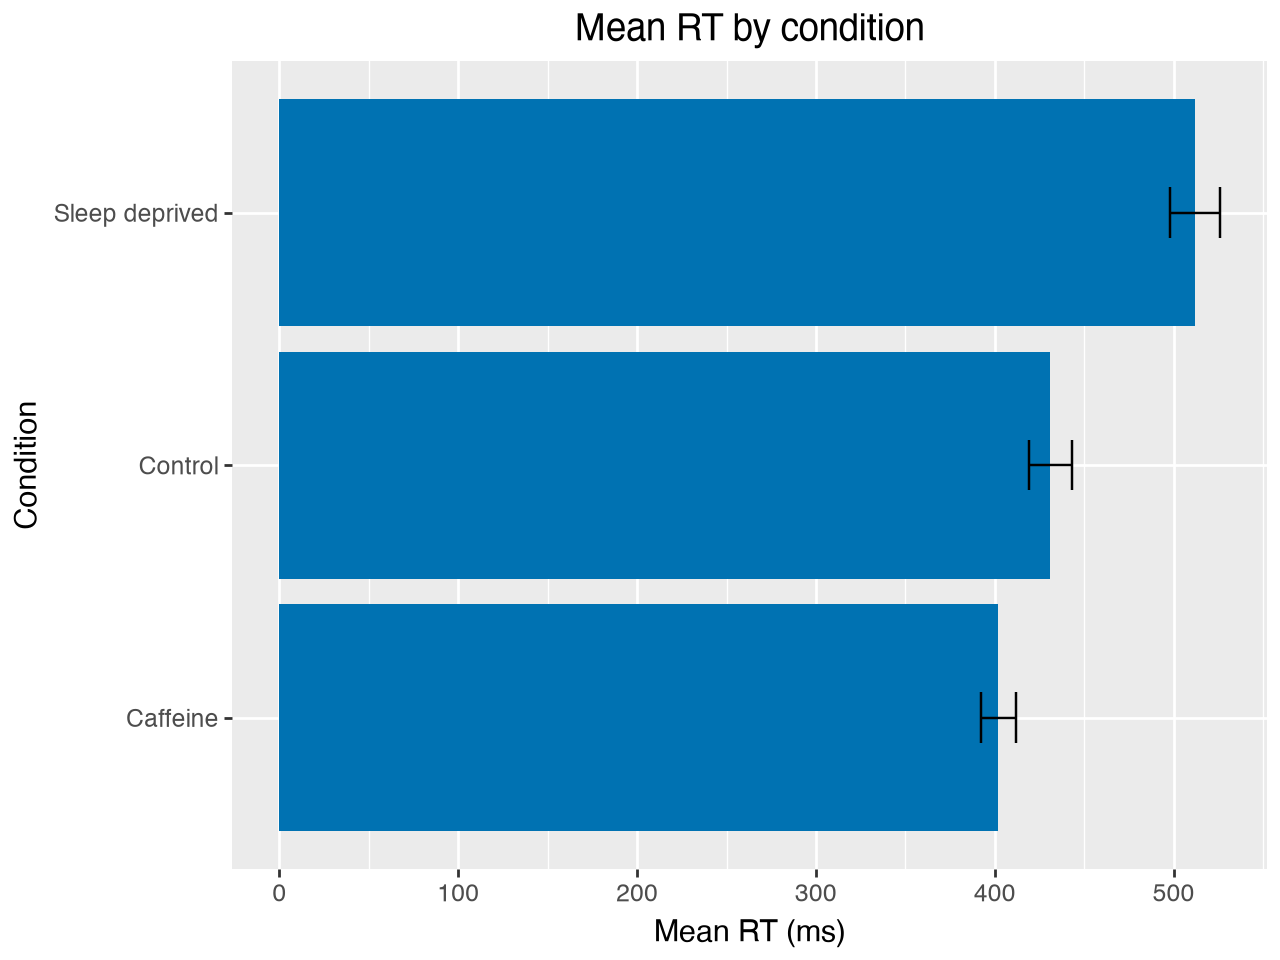

In [23]:
rt = pd.DataFrame({'condition': ['Control', 'Caffeine', 'Sleep deprived'],
                   'rt_ms': [431, 402, 512], 'se': [12, 10, 14]})
p = (ggplot(rt, aes('reorder(condition, rt_ms)', 'rt_ms'))
     + geom_col(fill='#0072B2')
     + geom_errorbar(aes(ymin='rt_ms - se', ymax='rt_ms + se'), width=0.2)
     + coord_flip()
     + labs(x='Condition', y='Mean RT (ms)', title='Mean RT by condition'))
p

In [24]:
%plotlint audit

Chartability audit: Mean RT by condition (13 pass, 1 fail, 5 partly checked, 2 your call, 29 n/a)
  [Fail] Small text size *
      LY201: Some text is 8.8 pt, below 9 pt (xtick, ytick).
      fix: `+ theme(text=element_text(size=11))` or a larger `base_size` in the theme, e.g. `theme_bw(base_size=12)`.
  [Partly checked] Content is only visual *
      A draft alt text is filled in above.
      -> Edit the alt text above so it says what you want a reader to conclude, and put it next to the chart in your notebook. Then check this box.
  [Partly checked] No title, summary, or caption *
      Title: “Mean RT by condition”. No subtitle or caption.
      -> The title names what is plotted. Could it say what to notice instead?
  [Partly checked] Metrics and variables are undefined
      Abbreviations not defined on the chart: “RT”.
      -> Will your readers know what these mean? Spell them out on the chart or define them in the caption.
  [Partly checked] Statistical uncertainty isn't clearly communicated
      The chart draws error bars.
      -> Say what the uncertainty marks show (SD, SE or a 95% CI), in the caption or a subtitle.
  [Partly checked] Visually apparent features and relationships are not described
      The draft alt text gives the extremes or the overall trend, not why they matter.
      -> Does your description name the pattern a sighted reader would notice first (a trend, a gap, an outlier)?
  [Your call] No explanation for purpose or for how to read *
      This chart is a bar chart.
      -> In a sentence next to the chart, say what question it answers.
  [Your call] No table *
      `data_table(p)` gives the 3 rows behind the chart.
      -> Show the data as a table under the chart, or say why readers don't need it.
  [Pass] Low contrast *
      Text meets 4.5:1 (3:1 for large text) and marks meet 3:1 against the background.
  [Pass] Color is used alone to communicate meaning
      Color isn't the only way to tell groups apart.
  [Pass] Meaningful elements can be distinguished from each other
      Marks don't hide each other and there aren't too many colors to tell apart.
  [Pass] Not CVD-friendly
      Colors stay distinguishable under simulated color-vision deficiencies.
  [Pass] Spacing is inappropriate
      No overlapping labels.
  [Pass] Reading level inappropriate *
      Too little text to score (8 words).
  [Pass] Information complexity is inappropriate
      Nothing is drawn that the reader has to decode (such as 3D).
  [Pass] Axis labels are unclear or missing
      Axes have human-readable labels.
  [Pass] Data density is inappropriate *
      The number of marks, lines and colors is readable.
  [Pass] Data in text is not human-readable
      Numbers and dates in the chart's text are formatted for people.
  [Pass] Space does not handle extremes
      No single value squashes the rest.
  [Pass] Design is not consistent and familiar
      Colors and theme match the other plots in this notebook.
  [Pass] Difficult chart type has no alternative
      A familiar chart type (bar chart).
  (29 tests don't apply to a static chart; * = critical)

To answer it in the notebook, print it as a checklist and paste that into a markdown cell under the chart. Automatic passes are pre-checked and the draft alt text is filled in for you to edit.

In [25]:
%plotlint audit p --markdown

#### Accessibility checklist: Mean RT by condition
<!-- plotnine-linter audit v1 draft=4fa16def -->

**Alt text** (a draft: edit it to say your takeaway):

> Mean RT by condition. Bar chart of Mean RT (ms) by Condition. Highest: Sleep deprived (512); lowest: Caffeine (402).

- [ ] Fix: **Small text size** (critical). LY201: Some text is 8.8 pt, below 9 pt (xtick, ytick). Fix: `+ theme(text=element_text(size=11))` or a larger `base_size` in the theme, e.g. `theme_bw(base_size=12)`.
- [ ] **Content is only visual** (critical). A draft alt text is filled in above. Edit the alt text above so it says what you want a reader to conclude, and put it next to the chart in your notebook. Then check this box.
- [ ] **No title, summary, or caption** (critical). Title: “Mean RT by condition”. No subtitle or caption. The title names what is plotted. Could it say what to notice instead?
  - Answer: 
- [ ] **Metrics and variables are undefined**. Abbreviations not defined on the chart: “RT”. Will your 

A student's answered checklist might look like this (shortened):

#### Accessibility checklist: Mean RT by condition
<!-- plotnine-linter audit v1 draft=4fa16def -->

**Alt text** (a draft: edit it to say your takeaway):

> Bar chart of mean reaction time in milliseconds for three conditions. Sleep-deprived participants were slowest (512 ms), about 80 ms slower than the control group; caffeine made them slightly faster (402 ms).

- [ ] Fix: **Small text size** (critical). LY201: Some text is 8.8 pt, below 9 pt (xtick, ytick). Fix: `+ theme(text=element_text(size=11))` or a larger `base_size` in the theme, e.g. `theme_bw(base_size=12)`.
- [x] **Content is only visual** (critical). A draft alt text is filled in above. Edit the alt text above so it says what you want a reader to conclude, and put it next to the chart in your notebook. Then check this box.
- [ ] **No title, summary, or caption** (critical). Title: “Mean RT by condition”. No subtitle or caption. The title names what is plotted. Could it say what to notice instead?
  - Answer: 
- [ ] **Metrics and variables are undefined**. Abbreviations not defined on the chart: “RT”. Will your readers know what these mean? Spell them out on the chart or define them in the caption.
  - Answer: 
- [x] **Statistical uncertainty isn't clearly communicated**. The chart draws error bars. Say what the uncertainty marks show (SD, SE or a 95% CI), in the caption or a subtitle.
  - Answer: Added a caption: "Error bars show ±1 standard error."
- [ ] **Visually apparent features and relationships are not described**. The draft alt text gives the extremes or the overall trend, not why they matter. Does your description name the pattern a sighted reader would notice first (a trend, a gap, an outlier)?
  - Answer: 
- [ ] **No explanation for purpose or for how to read** (critical). This chart is a bar chart. In a sentence next to the chart, say what question it answers.
  - Answer: 
- [ ] **No table** (critical). `data_table(p)` gives the 3 rows behind the chart. Show the data as a table under the chart, or say why readers don't need it.
  - Answer: 
- [x] Low contrast (checked automatically): Text meets 4.5:1 (3:1 for large text) and marks meet 3:1 against the background.
- [x] ...

`data_table(p)` gives the data behind a chart, for the *No table* item:

In [26]:
from plotnine_linter import data_table

data_table(p)

,Condition,Mean RT (ms)
0,Control,431
1,Caffeine,402
2,Sleep deprived,512


For grading, `plotnine-linter audit project.ipynb --check-answers` reads the checklists pasted into a notebook and lists unchecked boxes, empty answers, and alt text left exactly as drafted.

## Every plot at a glance

`%plotlint summary` lists each plot linted in this session (since the last `%plotlint reset`), with its findings. Students can use it as a checklist before submitting.

In [27]:
%plotlint summary

Plot,Cell,Errors,Warnings,Findings
1,[14],,,"CL301 `section` is shown by color alone, and in grayscale 'B' and 'C' look the same.ST301 The plot has no title.ST303 3 lines are matched to a legend."
2,[17],,1,"CL202 The colored values run from negative to positive, but the colormap `viridis` is sequential, so zero has no distinct color."
3,[18],,1,"CL203 Each of the 4 bars has its own color, but the colors don't stand for anything."
4,[19],,1,"AX207 The x-axis has a tick at 2018.5, but the plotted values are whole numbers."
5,[20],1,,LY103 Text 'Week' (xlabel) has a contrast of 1.9:1 against its background; it needs 4.5:1.
6,[22],,1,CL204 Marks colored #ff7f0e have a contrast of only 2.5:1 against the #ffffff background (WCAG asks 3:1).
7,[24],,,no issues


## From the command line

To lint a whole notebook without opening it (cells that fail, e.g. on missing data, are skipped):

```bash
plotnine-linter check project.ipynb
plotnine-linter check projects/*.ipynb --format json --save-images lint_images/
plotnine-linter audit project.ipynb                      # an accessibility checklist for every plot
plotnine-linter audit projects/*.ipynb --check-answers   # which checklist items are still open
```